In [1]:
import sys

print("Versión de Python:", sys.version)
print("Ejecutable:", sys.executable)

Versión de Python: 3.12.9 (main, Mar 17 2025, 21:06:20) [MSC v.1943 64 bit (AMD64)]
Ejecutable: c:\Users\cynth\OneDrive\Desktop\Laboratorio_VIT\.venv\Scripts\python.exe


In [2]:
from transformers import ViTImageProcessor, ViTForImageClassification

modelo_id = "google/vit-base-patch16-224"

processor = ViTImageProcessor.from_pretrained(modelo_id)

model = ViTForImageClassification.from_pretrained(modelo_id)

print("Modelo ViT cargado correctamente")
print("Cantidad de categorías:", model.config.num_labels)

c:\Users\cynth\OneDrive\Desktop\Laboratorio_VIT\.venv\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm
[transformers] `ViTImageProcessor` requires torchvision (not installed); falling back to `ViTImageProcessorPil` for backward compatibility. Install torchvision to use the default backend, or import `ViTImageProcessorPil` directly to silence this warning.
c:\Users\cynth\OneDrive\Desktop\Laboratorio_VIT\.venv\Lib\site-packages\huggingface_hub\file_download.py:149: UserWarning: `huggingface_hub` cache-system uses symlinks by default to efficiently store duplicated files but your machine does not support them in C:\Users\cynth\.cache\huggingface\hub\models--google--vit-base-patch16-224. Caching files will still work but in a degraded version that might require more space on your disk. This warning can be disabled by s

Modelo ViT cargado correctamente
Cantidad de categorías: 1000


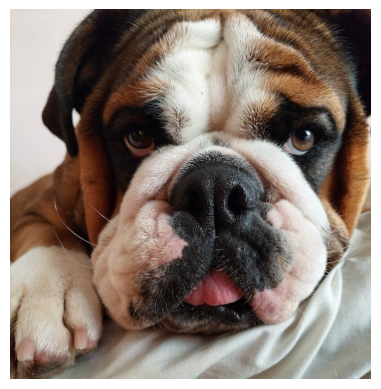

In [4]:
from PIL import Image
import matplotlib.pyplot as plt

# Abrir la fotografía
imagen = Image.open("Emma.jpg").convert("RGB")

# Mostrarla en el notebook
plt.imshow(imagen)
plt.axis("off")
plt.show()

In [5]:
import torch

# 1. Preparar la imagen
inputs = processor(images=imagen, return_tensors="pt")

# 2. Pasar la imagen por el modelo ViT
with torch.no_grad():
    outputs = model(**inputs)

# 3. Obtener las puntuaciones
logits = outputs.logits

# 4. Identificar la categoría con mayor puntuación
predicted_class_idx = logits.argmax(-1).item()

# 5. Mostrar la categoría predicha
categoria = model.config.id2label[predicted_class_idx]

print("ViT reconoce la imagen como:", categoria)

ViT reconoce la imagen como: boxer


In [6]:
# Convertir las puntuaciones en probabilidades
probabilidades = torch.softmax(logits, dim=-1)

# Obtener las 5 categorías con mayor puntuación
valores, indices = torch.topk(probabilidades, 5)

# Mostrar resultados
for i in range(5):
    categoria = model.config.id2label[indices[0][i].item()]
    porcentaje = valores[0][i].item() * 100

    print(f"{i+1}. {categoria}: {porcentaje:.2f}%")

1. boxer: 50.21%
2. bull mastiff: 34.69%
3. Saint Bernard, St Bernard: 4.12%
4. French bulldog: 2.22%
5. Brabancon griffon: 0.57%


In [9]:
# Buscar todas las categorías que contienen "bulldog"

for indice, nombre in model.config.id2label.items():
    if "bulldog" in nombre.lower():
        porcentaje = probabilidades[0, indice].item() * 100

        print(f"{indice} - {nombre}: {porcentaje:.4f}%")

245 - French bulldog: 2.2241%


In [8]:
# Buscar la categoría English bulldog
for indice, nombre in model.config.id2label.items():
    if "english bulldog" in nombre.lower():
        porcentaje = probabilidades[0, indice].item() * 100
        print("Categoría:", nombre)
        print(f"Puntuación: {porcentaje:.4f}%")

In [10]:
import pandas as pd

categorias = pd.DataFrame(
    model.config.id2label.items(),
    columns=["ID", "Categoria"]
)

display(categorias)

,ID,Categoria
0,0,"tench, Tinca tinca"
1,1,"goldfish, Carassius auratus"
2,2,"great white shark, white shark, man-eater, man..."
3,3,"tiger shark, Galeocerdo cuvieri"
4,4,"hammerhead, hammerhead shark"
...,...,...
995,995,earthstar
996,996,"hen-of-the-woods, hen of the woods, Polyporus ..."
997,997,bolete
998,998,"ear, spike, capitulum"
